# 08 — Explore OSM indicator structure

This notebook performs exploratory multivariate and spatial analysis of the intrinsic OSM indicators produced by Notebook 07 for the 895 IBGE 1 km cells intersecting Petrópolis.

It evaluates distributions, missingness, zero inflation, Spearman redundancy, PCA gradients and global Moran's I. It does **not** query the ohsome API and does **not** create clusters. PCA is used only as exploratory dimensionality reduction and must not be interpreted as a maturity score.

The full executable analysis is maintained in `scripts/notebook08_explore_indicator_structure.py` so the same logic can be run reproducibly from GitHub Actions and from this notebook.


Executing: /home/runner/work/sotm-br-2026/sotm-br-2026/scripts/notebook08_explore_indicator_structure.py


Python: 3.12.13
Indicator rows: 895
Grid rows: 895
Grid CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "SIRGAS 2000", "datum": {"type": "GeodeticReferenceFrame", "name": "Sistema de Referencia Geocentrico para las AmericaS 2000", "ellipsoid": {"name": "GRS 1980", "semi_major_axis": 6378137, "inverse_flattening": 298.257222101}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, "scope": "Horizontal component of 3D system.", "area": "Latin America - Central America and South America - onshore and offshore. Brazil - onshore and offshore.", "bbox": {"south_latitude": -59.87, "west_longitude": -122.19, "north_latitude": 32.72, "east_longitude": -25.28}, "id": {"authority": "EPSG", "code": 4674}}
PASS — Notebook 07 outputs cover the same 895

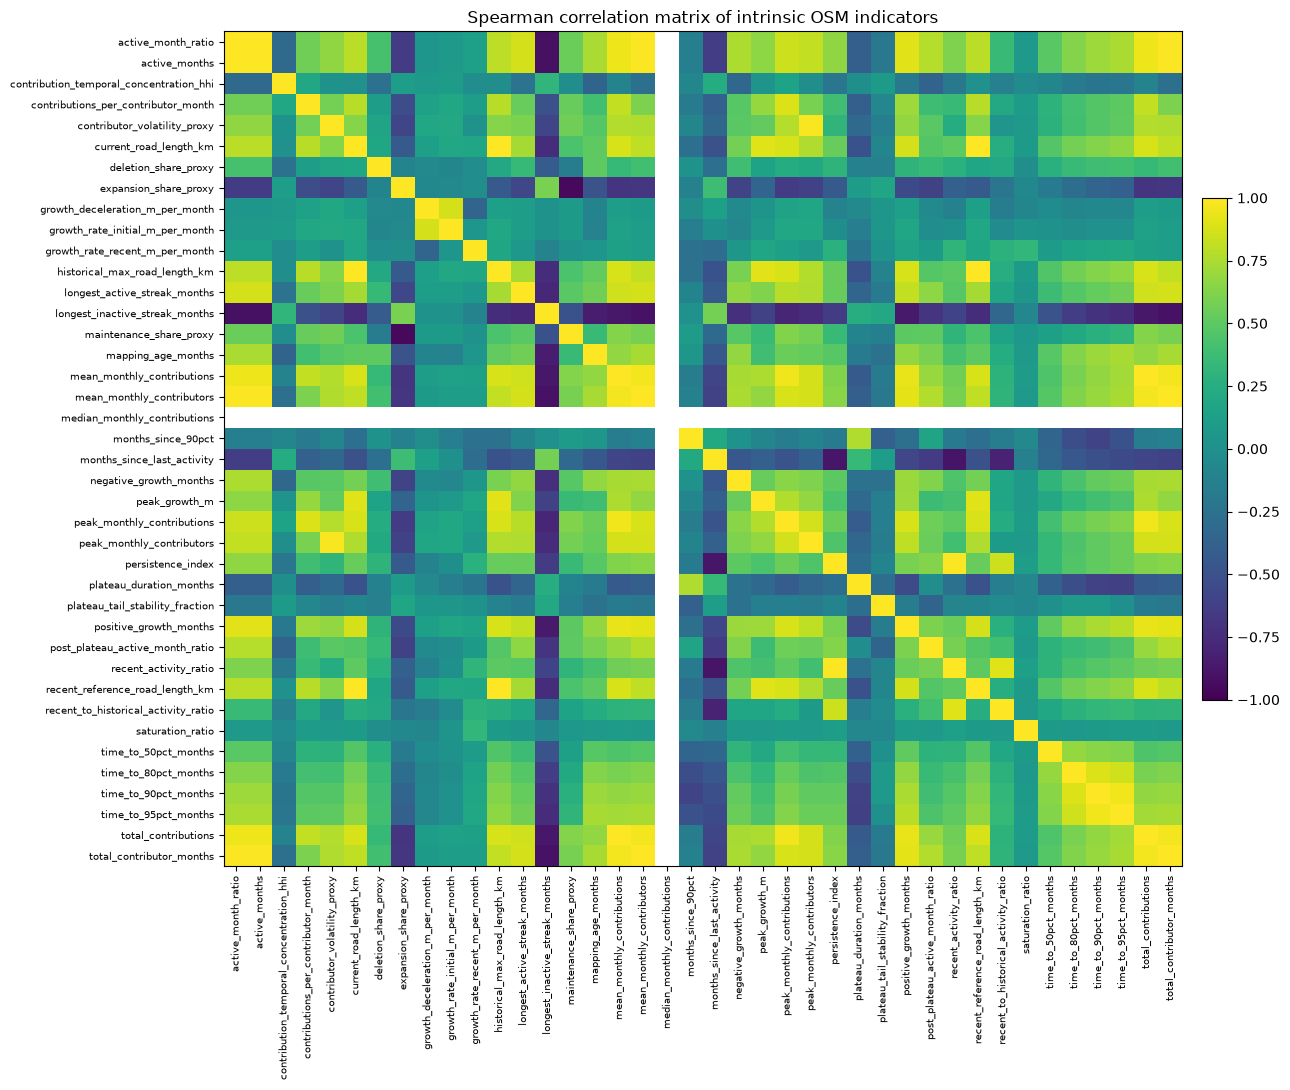


PCA preprocessing diagnostics:
                               variable  missing_n  median_used_for_pca  winsor_lower_1pct  winsor_upper_99pct
                 current_road_length_km          0             2.056780           0.000000           13.089868
                     mapping_age_months        102           134.000000          61.380000          222.000000
                          peak_growth_m          0          1297.460000           0.000000         7897.185000
        growth_deceleration_m_per_month        102             0.000000         -60.880565          187.807183
                   time_to_90pct_months        114            61.000000           0.000000          190.120000
                     months_since_90pct        114            72.000000           6.000000          207.000000
                plateau_duration_months        146            69.000000          16.000000          158.780000
                     active_month_ratio          0             0.035714         

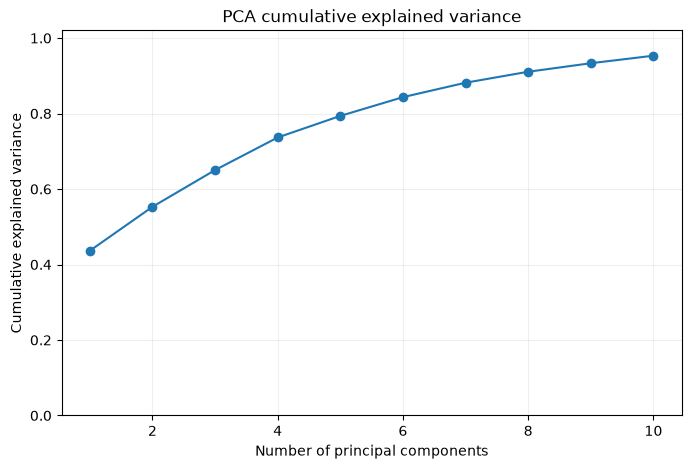


Global Moran diagnostics:
                               variable   n  moran_i  p_sim     z_sim  islands
                    total_contributions 895 0.695840  0.001 36.071291        8
                     active_month_ratio 895 0.630760  0.001 31.836775        8
                 current_road_length_km 895 0.628223  0.001 33.149274        8
                     mapping_age_months 793 0.539089  0.001 25.534935        7
                      persistence_index 895 0.504308  0.001 27.905265        8
                  recent_activity_ratio 895 0.470766  0.001 24.377618        8
                   time_to_90pct_months 781 0.406120  0.001 18.870596        7
                plateau_duration_months 749 0.258401  0.001 11.088935        7
contribution_temporal_concentration_hhi 795 0.175945  0.001  8.140888        7


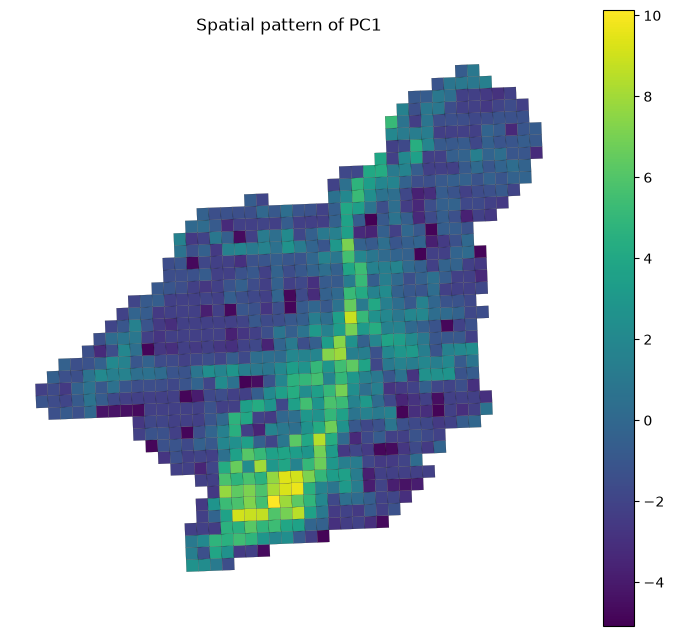

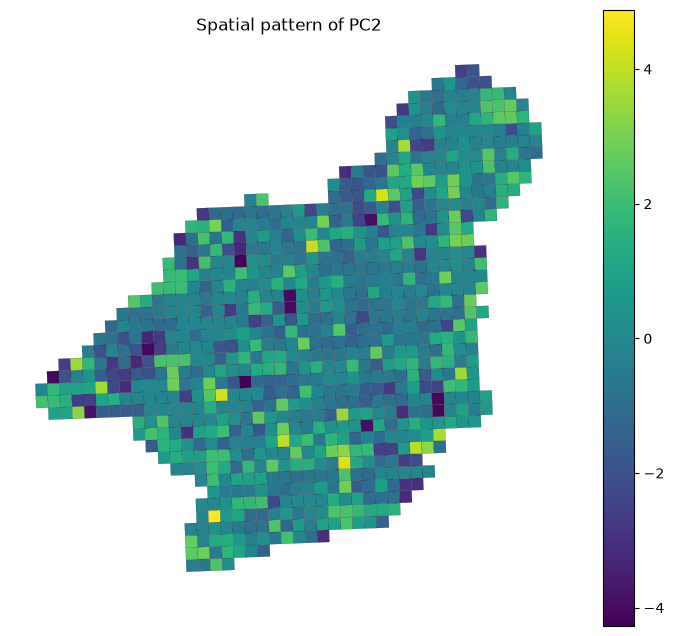

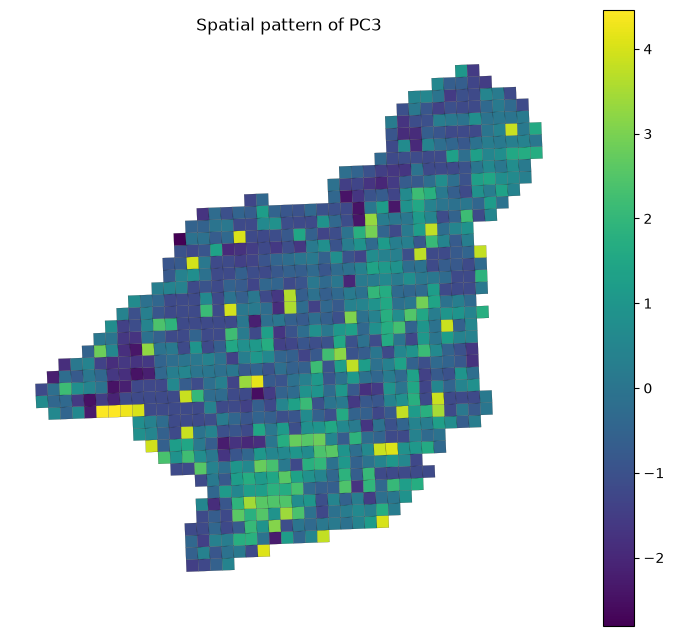


Notebook 08 quality control:
                               check status
                            rows_895   PASS
                          ids_unique   PASS
                 pca_scores_complete   PASS
            pca_variance_sums_to_one   PASS
pca_pc1_not_single_feature_dominated   PASS
        correlation_matrix_symmetric   PASS
               moran_results_created   PASS
          moran_i_finite_when_tested   PASS
                  output_files_exist   PASS
status
PASS    9
FAIL    0

Saved outputs:
/home/runner/work/sotm-br-2026/sotm-br-2026/data/processed/Petropolis/petropolis_osm_indicator_feature_matrix_895_cells.parquet
/home/runner/work/sotm-br-2026/sotm-br-2026/data/processed/Petropolis/petropolis_osm_pca_loadings.csv
/home/runner/work/sotm-br-2026/sotm-br-2026/data/processed/Petropolis/petropolis_osm_pca_explained_variance.csv
/home/runner/work/sotm-br-2026/sotm-br-2026/data/processed/Petropolis/petropolis_osm_spearman_correlation.csv
/home/runner/work/sotm-br-2026/sotm

{'__name__': '__main__',
 '__doc__': None,
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '../scripts/notebook08_explore_indicator_structure.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__(name, globals=None, locals=None, fromlist

In [1]:
from pathlib import Path
import runpy

script = Path('scripts/notebook08_explore_indicator_structure.py')
if not script.exists():
    script = Path('..') / 'scripts' / 'notebook08_explore_indicator_structure.py'

print('Executing:', script.resolve())
runpy.run_path(str(script), run_name='__main__')


## Interpretation boundary

All outputs characterize intrinsic OpenStreetMap history and structure. A long plateau, high persistence, high road density or high intrinsic saturation does not demonstrate external completeness or real-world accuracy.

The next step is to use the redundancy, PCA and spatial-autocorrelation diagnostics to design and test a defensible cell typology rather than assigning semantic classes directly from a single composite score.
